In [26]:
# Cargamos las librerías necesarias y declaramos las constantes utilizadas
import eficiencia_maquinas as efma
import importlib
importlib.reload(efma) # Recordad que hicimos esto para saltarnos la caché de jupyter notebook y que no tenga que volver a abrir el fichero importado
import pandas as pd
import matplotlib.pyplot as plt

In [33]:
# ¿Se pueden comparar directamente todos los registros? ¿Has detectado problemas de calidad que puedan distorsionar el diagnóstico? NOTA: puedes usar drop_duplicates() y dropna().
# Extraemos los datos del fichero csv que nos dan
datos_brutos = pd.read_csv("lecturas_maquinas.csv")
duplicados, nulos, datos_limpios = efma.limpiar_datos(datos_brutos)
print(f"Nº de duplicados: {duplicados}\nNº de nulos: {nulos}\nTotal registros depurados: {len(datos_limpios)}")
print(f"La calidad de los datos es del {round(len(datos_limpios)*100/len(datos_brutos),2)}%")

Nº de duplicados: 2
Nº de nulos: 4
Total registros depurados: 116
La calidad de los datos es del 95.08%


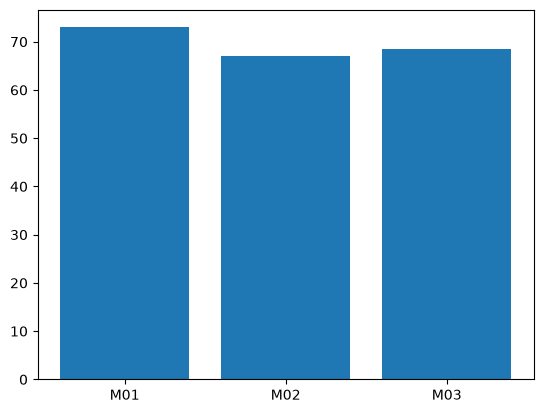

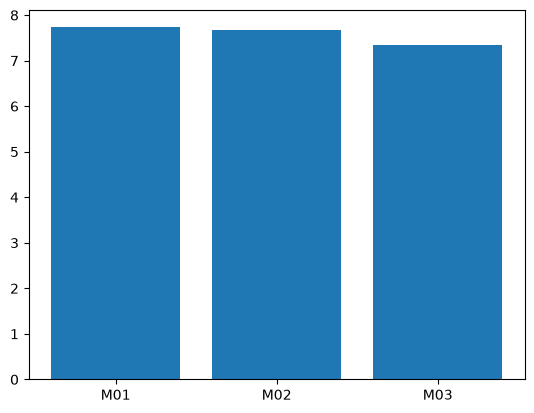

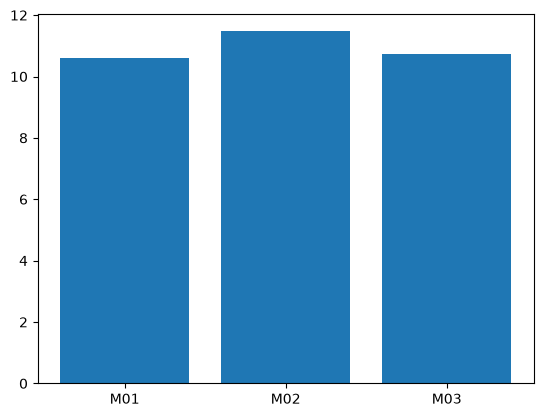

  maquina  num_registros  media_carga  media_consumo  media_temperatura  \
0     M01             39        72.97           7.73              71.82   
1     M02             39        66.97           7.68              79.86   
2     M03             38        68.45           7.34              68.93   

   indicador_carga_consumo  
0                    10.60  
1                    11.47  
2                    10.72  


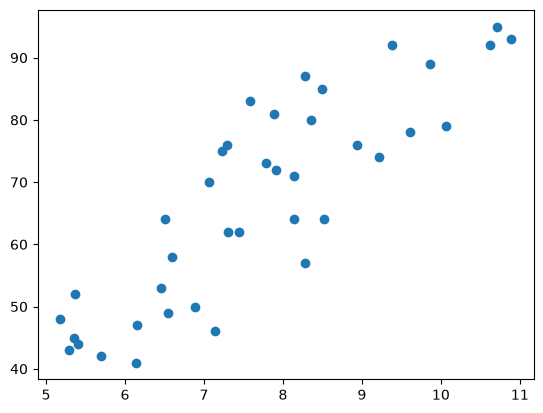

In [34]:
# ¿Qué máquina o máquinas merecen una revisión de su eficiencia energética? Aporta evidencias teniendo en cuenta tanto el consumo como el trabajo realizado. NOTA: puedes crear un indicador propio que relacione consumo_kwh con carga_pct, y debes explicar sus limitaciones.
datos_energeticos = []
# for maquina in ['M01','M02','M03'] :
for maquina in datos_limpios["maquina"].unique() :
    datos_energeticos.append(efma.obtener_datos_energeticos(datos_limpios,maquina))
datos_energeticos_total = pd.DataFrame(datos_energeticos)
plt.bar(datos_energeticos_total["maquina"],datos_energeticos_total["media_carga"])
plt.show()
plt.bar(datos_energeticos_total["maquina"],datos_energeticos_total["media_consumo"])
plt.show()
plt.bar(datos_energeticos_total["maquina"],datos_energeticos_total["indicador_carga_consumo"])
plt.savefig("grafica_maq2_comportamiento_extraño.jpg")
plt.show()

print(datos_energeticos_total)

# Vemos que la máquina 2 tiene excesivo consumo en el ratio consumo/carga comparado con el resto. Veamos en un diagrama de dispersión cómo se comporta la carga y el consumo para esa máquina
datos_maq2 = datos_limpios[datos_limpios["maquina"] == 'M02']
plt.scatter(datos_maq2["consumo_kwh"],datos_maq2["carga_pct"])

